<a href="https://colab.research.google.com/github/Brad3017/CreditScoring_system/blob/main/notebooks/credit_scoring_modelpipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable credit scoring for Kenyan MSMEs: data and model

**Part A: Data preparation and synthetic data generation**
audit the source data, check it carries real signal, generate 5,000 Kenyan synthetic records, validate them, and explore them.

**Part B: Model training, evaluation and export**
compare models, tune XGBoost, test class weighting, set risk bands, run the final test on 240 real held-out records, explain predictions with SHAP, and export the files the Django system loads.




---
# Part A · Data preparation and synthetic data generation

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm, ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score
import xgboost as xgb

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 140)

# Colab: upload the CSV to the session, or point this at your Google Drive copy,
# e.g. "/content/drive/MyDrive/Credit_Dataset/bangladesh_sme_1200_records.csv"
file_path = "/content/drive/MyDrive/Credit_Dataset/bangladesh_sme_1200_records.csv"
BDT_TO_KES = 1.06   # mid-market rate, Nov 2026 (Wise ~1.06). Record the date you use in the report.
N_SYNTHETIC = 5000

##Load the source data

In [2]:
from google.colab import drive
drive.mount('/content/drive')


file_path = "/content/drive/MyDrive/Credit_Dataset/bangladesh_sme_1200_records.csv"
raw = pd.read_csv(file_path)
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print("Default (missed payment) rate:", round(raw["target_missed_payment"].mean(), 3))
print("Provided split:", raw["split"].value_counts().to_dict())
raw.head(3).T

Mounted at /content/drive
Shape: (1200, 27)
Missing values: 0
Default (missed payment) rate: 0.252
Provided split: {'train': 960, 'test': 240}


,0,1,2
business_id,SME0001,SME0002,SME0003
sector,Manufacturing,Retail,Retail
business_age_years,15,16,17
legal_status,Limited,Sole,Sole
division,Dhaka,Rajshahi,Dhaka
location_type,Urban,Urban,Urban
employees_count,23,13,7
monthly_revenue_bdt,403110,1562133,655507
monthly_profit_bdt,96506,428067,175415
existing_loans,Yes,Yes,Yes


### Leakage check
`missed_payment_last_12m` is a candidate predictor. If it records the outcome itself, the model would be shown the answer.

In [3]:
pd.crosstab(raw["missed_payment_last_12m"], raw["target_missed_payment"])

target_missed_payment,0,1
missed_payment_last_12m,,
No,897,0
Yes,0,303


The two columns agree on **every row**, so `missed_payment_last_12m` is the target under another name. It is removed. Keeping it would give a near-perfect but meaningless score.

### Text columns
The four description columns are free text. The check below shows they follow fixed templates, a sign that the source dataset is itself generated rather than collected from a lender.

In [4]:
for c in ["business_description", "repayment_plan_description"]:
    print(f"--- {c}\n{raw[c].iloc[0][:220]}\n{raw[c].iloc[1][:220]}\n")

--- business_description
Food processing in Dhaka City, Dhaka division. Operating 15 years with 23 employees. Urban market with strong competition. Monthly revenue approximately 403K BDT. Peak sales during Eid festivals and wedding season. Stron
Furniture store in Sirajganj, Rajshahi division. Operating 16 years with 13 employees. Urban market with strong competition. Monthly revenue approximately 1562K BDT. Peak sales during Eid festivals and wedding season. St

--- repayment_plan_description
Monthly installment 26K BDT from business revenue. Peak season sales provide repayment cushion. Maintain 30% of revenue for loan servicing. 0 previous loans repaid successfully. Cashflow stability rated 5/5. Owner commit
Monthly installment 104K BDT from business revenue. Peak season sales provide repayment cushion. Maintain 30% of revenue for loan servicing. 2 previous loans repaid successfully. Cashflow stability rated 3/5. Owner commi




| Kept as | Source | Reason |
|---|---|---|
| sector, legal_status, location_type, loan_purpose | as is | collected on the form |
| business_age_years, employees_count | as is | collected on the form |
| monthly_revenue | monthly_revenue_bdt | converted to KES later |
| **profit_margin** | profit ÷ revenue | modelled as a ratio so generated profit never exceeds revenue |
| **loan_to_revenue** | loan amount ÷ revenue | keeps the size of the loan relative to the business |
| preferred_tenure_months, existing_loans, prior_loan_count, late_payment_history, collateral_level, cashflow_stability, repayment_confidence, owner_education, days_payable_outstanding | as is | collected on the form |

Dropped: `business_id`, `division` (replaced by Kenyan county later), `missed_payment_last_12m` (leak), the four text columns, `split` (used, then dropped).

In [5]:
TARGET = "target_missed_payment"
ORDINAL = {
    "late_payment_history": ["Never", "Rarely", "Sometimes"],
    "collateral_level": ["Low", "Moderate", "High"],
    "owner_education": ["Primary", "Secondary", "Higher Secondary", "Bachelor's", "Master's"],
    "existing_loans": ["No", "Yes"],
}
NOMINAL = ["sector", "legal_status", "location_type", "loan_purpose"]
INTEGER = ["business_age_years", "employees_count", "prior_loan_count", "preferred_tenure_months",
           "cashflow_stability", "repayment_confidence", "days_payable_outstanding"]

def select(d):
    return pd.DataFrame({
        "sector": d.sector, "legal_status": d.legal_status, "location_type": d.location_type,
        "loan_purpose": d.loan_purpose, "business_age_years": d.business_age_years,
        "employees_count": d.employees_count, "monthly_revenue": d.monthly_revenue_bdt,
        "profit_margin": d.monthly_profit_bdt / d.monthly_revenue_bdt,
        "loan_to_revenue": d.loan_amount_bdt / d.monthly_revenue_bdt,
        "preferred_tenure_months": d.preferred_tenure_months, "existing_loans": d.existing_loans,
        "prior_loan_count": d.prior_loan_count, "late_payment_history": d.late_payment_history,
        "collateral_level": d.collateral_level, "cashflow_stability": d.cashflow_stability,
        "repayment_confidence": d.repayment_confidence, "owner_education": d.owner_education,
        "days_payable_outstanding": d.days_payable_outstanding, TARGET: d.target_missed_payment,
    })

# The provided split is respected. The generator only ever sees the TRAIN rows;
# the 240 TEST rows stay untouched as real data for honest evaluation.
real_train = select(raw[raw.split == "train"]).reset_index(drop=True)
real_test  = select(raw[raw.split == "test"]).reset_index(drop=True)
print("Real train:", real_train.shape, "| Real test (held out):", real_test.shape)

Real train: (960, 19) | Real test (held out): (240, 19)


## Checking whether there is real signal in the source data
Before generating anything, I check whether the features predict the outcome in the real rows. A simple logistic regression with 5-fold cross-validation on the training rows is used to show this.

In [6]:
def encode(d, columns=None):
    o = d.drop(columns=[TARGET]).copy()
    for c, cats in ORDINAL.items():
        o[c] = o[c].map({k: i for i, k in enumerate(cats)})
    o = pd.get_dummies(o, columns=NOMINAL, dtype=float)
    return o.reindex(columns=columns, fill_value=0) if columns is not None else o

X_real_train = encode(real_train); COLS = list(X_real_train.columns)
X_real_test = encode(real_test, COLS)
logreg = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
s = cross_val_score(logreg(), X_real_train, real_train[TARGET], cv=cv, scoring="roc_auc")
print(f"Logistic regression, 5-fold CV on real training rows: AUC {s.mean():.3f} ± {s.std():.3f}")

Logistic regression, 5-fold CV on real training rows: AUC 0.913 ± 0.018


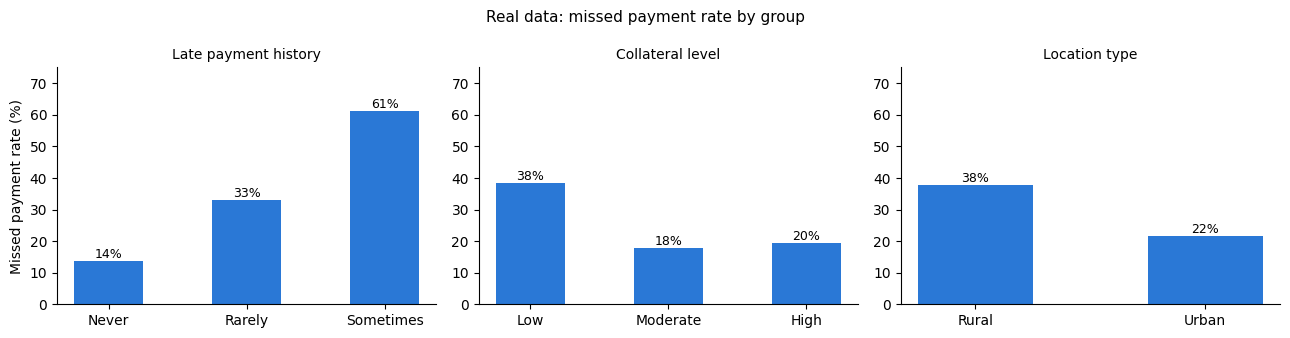

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["late_payment_history", "collateral_level", "location_type"]):
    order = ORDINAL.get(c, sorted(real_train[c].unique()))
    rates = real_train.groupby(c)[TARGET].mean().reindex(order) * 100
    ax.bar(rates.index, rates.values, width=0.5, color="#2a78d6")
    for i, v in enumerate(rates.values): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_title(c.replace("_", " ").capitalize(), fontsize=10); ax.set_ylim(0, 75)
    ax.spines[["top", "right"]].set_visible(False); ax.set_ylabel("Missed payment rate (%)" if c == "late_payment_history" else "")
fig.suptitle("Real data: missed payment rate by group", fontsize=11); plt.tight_layout(); plt.show()

The rate rises clearly with late-payment history and falls with collateral, so the source data carries signal worth preserving.

## Data Generator: class-conditional Gaussian copula
**The idea, in plain terms.** Each column keeps its own real distribution, called its *marginal*. The *copula* captures how columns move together, for example lower cash-flow stability alongside more late payments. It does this by converting every column to a normal score and storing their correlation matrix.

**Class-conditional** means one copula is fitted to the businesses that missed a payment and a separate one to those that did not. Each synthetic row is generated from one of the two, so the difference between payers and non-payers is built into the data. It is not invented by a rule.

Categorical columns are handled as SDV's Gaussian copula handles them: each category occupies a slice of the 0–1 range in proportion to its frequency. Numeric values are sampled by interpolating between real values, so new rows are similar to the real ones without copying them.

*Reference:* Patki, Wedge & Veeramachaneni (2016), *The Synthetic Data Vault*, IEEE DSAA.

In [8]:
class ClassConditionalGaussianCopula:
    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)

    def _normal_scores(self, g):
        Z = {}
        for c in self.cols:
            if c in self.cats:
                cats = self.cats[c]
                p = g[c].value_counts(normalize=True).reindex(cats, fill_value=0).values
                edges = np.concatenate([[0], np.cumsum(p)])
                idx = g[c].map({k: i for i, k in enumerate(cats)}).values
                u = edges[idx] + self.rng.random(len(g)) * (edges[idx + 1] - edges[idx])
            else:
                u = (g[c].rank(method="average").values - 0.5) / len(g)
            Z[c] = norm.ppf(np.clip(u, 1e-6, 1 - 1e-6))
        return pd.DataFrame(Z)

    def fit(self, df):
        self.cols = [c for c in df.columns if c != TARGET]
        self.cats = {c: (ORDINAL[c] if c in ORDINAL else list(df[c].value_counts().index))
                     for c in self.cols if c in ORDINAL or c in NOMINAL}
        self.models = {}
        for k, g in df.groupby(TARGET):
            g = g[self.cols].reset_index(drop=True)
            corr = np.corrcoef(self._normal_scores(g).values, rowvar=False)
            w, v = np.linalg.eigh(corr)                      # keep the matrix valid
            corr = v @ np.diag(np.clip(w, 1e-6, None)) @ v.T
            d = np.sqrt(np.diag(corr)); corr = corr / np.outer(d, d)
            marg = {c: (np.cumsum(g[c].value_counts(normalize=True).reindex(self.cats[c], fill_value=0).values)
                        if c in self.cats else np.sort(g[c].values.astype(float))) for c in self.cols}
            self.models[k] = (corr, marg)
        self.default_rate = df[TARGET].mean()
        return self

    def sample(self, n):
        n1 = int(round(n * self.default_rate)); parts = []
        for k, m in [(0, n - n1), (1, n1)]:
            corr, marg = self.models[k]
            U = norm.cdf(self.rng.multivariate_normal(np.zeros(len(self.cols)), corr, size=m))
            out = {}
            for j, c in enumerate(self.cols):
                if c in self.cats:
                    idx = np.searchsorted(marg[c], U[:, j], side="right").clip(0, len(self.cats[c]) - 1)
                    out[c] = np.array(self.cats[c])[idx]
                else:
                    v = marg[c]; q = np.interp(U[:, j] * (len(v) - 1), np.arange(len(v)), v)
                    out[c] = np.round(q).astype(int) if c in INTEGER else q
            part = pd.DataFrame(out); part[TARGET] = k; parts.append(part)
        return pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

generator = ClassConditionalGaussianCopula(seed=SEED).fit(real_train)
synthetic = generator.sample(N_SYNTHETIC)
print("Synthetic rows:", synthetic.shape, "| default rate:", round(synthetic[TARGET].mean(), 3))
synthetic.head()

Synthetic rows: (5000, 19) | default rate: 0.252


,sector,legal_status,location_type,loan_purpose,business_age_years,employees_count,monthly_revenue,profit_margin,loan_to_revenue,preferred_tenure_months,existing_loans,prior_loan_count,late_payment_history,collateral_level,cashflow_stability,repayment_confidence,owner_education,days_payable_outstanding,target_missed_payment
0,Services,Sole,Urban,Inventory,5,22,2.475713e+06,0.222363,1.563144,18,Yes,0,Never,Moderate,5,1,Higher Secondary,40,0
1,Retail,Sole,Urban,Inventory,19,13,2.667191e+06,0.273383,0.576770,12,Yes,0,Never,Moderate,3,2,Secondary,75,0
2,Retail,Sole,Urban,Equipment,14,8,2.216115e+05,0.349254,1.410747,12,Yes,1,Never,Low,4,4,Master's,40,0
3,Services,Sole,Rural,Renovation,4,13,3.845810e+05,0.209021,0.519614,18,Yes,1,Never,High,5,3,Bachelor's,30,0
4,Retail,Sole,Urban,Renovation,14,24,1.063766e+06,0.224633,2.325473,12,Yes,0,Never,High,2,2,Primary,75,0


## Validation


### Fidelity: distributions

In [9]:
num = ["business_age_years", "employees_count", "monthly_revenue", "profit_margin", "loan_to_revenue",
       "preferred_tenure_months", "prior_loan_count", "cashflow_stability", "repayment_confidence", "days_payable_outstanding"]
fid = pd.DataFrame({
    "real_mean": real_train[num].mean(), "synthetic_mean": synthetic[num].mean(),
    "real_std": real_train[num].std(), "synthetic_std": synthetic[num].std(),
    "KS_statistic": [ks_2samp(real_train[c], synthetic[c]).statistic for c in num],
}).round(3)
fid

,real_mean,synthetic_mean,real_std,synthetic_std,KS_statistic
business_age_years,10.183,10.096,5.440,5.502,0.016
employees_count,15.855,15.938,10.920,10.957,0.007
monthly_revenue,1446733.404,1453332.867,881491.097,886894.202,0.011
profit_margin,0.245,0.245,0.075,0.075,0.009
loan_to_revenue,1.507,1.501,0.568,0.567,0.011
preferred_tenure_months,18.750,18.714,7.655,7.563,0.006
prior_loan_count,1.256,1.250,0.991,0.987,0.003
cashflow_stability,3.322,3.313,1.103,1.110,0.007
repayment_confidence,3.639,3.623,1.075,1.086,0.005
days_payable_outstanding,42.901,42.932,26.406,26.061,0.008


A KS statistic near 0 means the two distributions are nearly the same. Below about 0.05 is a close match.

In [10]:
rows = []
for c in list(ORDINAL) + NOMINAL:
    r = real_train[c].value_counts(normalize=True); s_ = synthetic[c].value_counts(normalize=True)
    for k in r.index: rows.append({"column": c, "category": k, "real_%": 100 * r[k], "synthetic_%": 100 * s_.get(k, 0)})
pd.DataFrame(rows).round(1)

,column,category,real_%,synthetic_%
0,late_payment_history,Never,65.4,64.8
1,late_payment_history,Rarely,17.9,18.6
2,late_payment_history,Sometimes,16.7,16.6
3,collateral_level,High,35.2,34.9
4,collateral_level,Low,33.1,34.0
5,collateral_level,Moderate,31.7,31.1
6,owner_education,Higher Secondary,24.3,24.0
7,owner_education,Secondary,22.5,21.9
8,owner_education,Bachelor's,20.9,20.8
9,owner_education,Primary,18.8,18.6


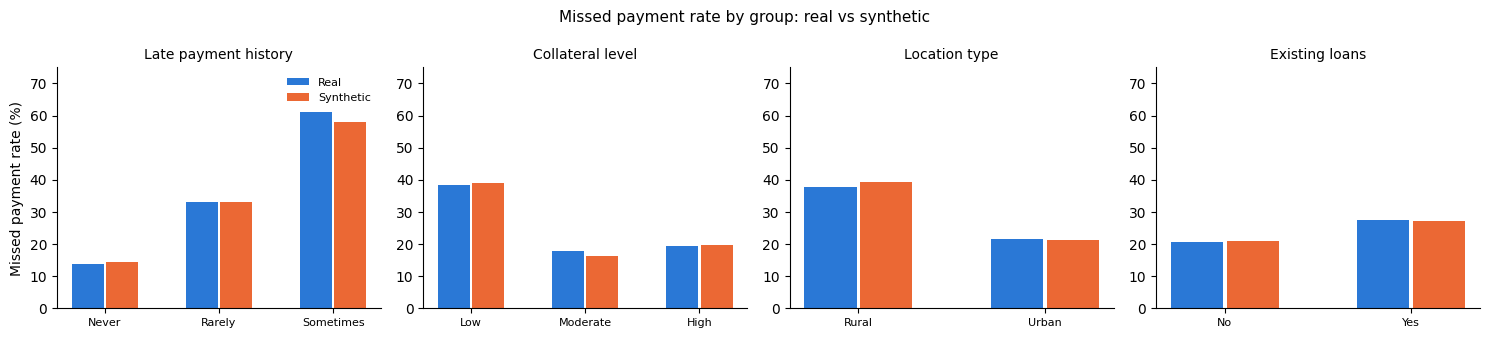

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, c in zip(axes, ["late_payment_history", "collateral_level", "location_type", "existing_loans"]):
    order = ORDINAL.get(c, sorted(real_train[c].unique())); x = np.arange(len(order))
    r = real_train.groupby(c)[TARGET].mean().reindex(order) * 100
    s_ = synthetic.groupby(c)[TARGET].mean().reindex(order) * 100
    ax.bar(x - 0.15, r.values, 0.28, label="Real", color="#2a78d6")
    ax.bar(x + 0.15, s_.values, 0.28, label="Synthetic", color="#eb6834")
    ax.set_xticks(x, order, fontsize=8); ax.set_title(c.replace("_", " ").capitalize(), fontsize=10)
    ax.set_ylim(0, 75); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Missed payment rate (%)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Missed payment rate by group: real vs synthetic", fontsize=11); plt.tight_layout(); plt.show()

In [12]:
corr = pd.DataFrame({
    "real": [real_train[c].corr(real_train[TARGET]) for c in num],
    "synthetic": [synthetic[c].corr(synthetic[TARGET]) for c in num]}, index=num).round(3)
corr["difference"] = (corr.synthetic - corr.real).round(3)
corr

,real,synthetic,difference
business_age_years,-0.057,-0.049,0.008
employees_count,-0.062,-0.085,-0.023
monthly_revenue,-0.102,-0.090,0.012
profit_margin,-0.094,-0.074,0.020
loan_to_revenue,0.252,0.269,0.017
preferred_tenure_months,0.020,0.014,-0.006
prior_loan_count,0.145,0.122,-0.023
cashflow_stability,-0.274,-0.285,-0.011
repayment_confidence,0.068,0.104,0.036
days_payable_outstanding,0.130,0.153,0.023


### Utility: train on synthetic, test on real (TSTR)
This is the standard test. Two models are trained, one on the real training rows and one on synthetic rows, and **both are scored on the same 240 real held-out rows**. If the synthetic-trained model scores close to the real-trained one, the synthetic data has kept what matters for prediction. Five generator seeds show the result is stable.

In [13]:
models = {
    "Logistic regression": logreg,
    "XGBoost": lambda: xgb.XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                         subsample=0.8, colsample_bytree=0.8, random_state=0),
}
y_test = real_test[TARGET]
results = []
for name, make in models.items():
    trtr = roc_auc_score(y_test, make().fit(X_real_train, real_train[TARGET]).predict_proba(X_real_test)[:, 1])
    tstr = []
    for seed in range(5):
        syn = ClassConditionalGaussianCopula(seed=seed).fit(real_train).sample(N_SYNTHETIC)
        tstr.append(roc_auc_score(y_test, make().fit(encode(syn, COLS), syn[TARGET]).predict_proba(X_real_test)[:, 1]))
    results.append({"model": name, "train real → test real": trtr,
                    "train synthetic → test real (mean of 5)": np.mean(tstr), "± std": np.std(tstr)})
pd.DataFrame(results).round(3)

,model,train real → test real,train synthetic → test real (mean of 5),± std
0,Logistic regression,0.895,0.883,0.004
1,XGBoost,0.944,0.884,0.010


**Reading this.** For logistic regression, synthetic training reaches almost the same AUC as real training. XGBoost trained on real data scores higher than XGBoost trained on synthetic data. That is because a Gaussian copula keeps pairwise relationships but not every non-linear interaction in the source. The report should state this: models trained on this data are, if anything, slightly pessimistic about what the source patterns allow.

### No memorisation: distance to closest record
For each synthetic row, this finds the nearest real training row on the standardised numeric columns. As a reference the same is done for the real test rows, which are different real businesses. If synthetic rows were near copies, their distances would be much smaller than the reference.

In [14]:
from sklearn.neighbors import NearestNeighbors
sc = StandardScaler().fit(real_train[num])
nn = NearestNeighbors(n_neighbors=1).fit(sc.transform(real_train[num]))
d_syn = nn.kneighbors(sc.transform(synthetic[num]))[0].ravel()
d_ref = nn.kneighbors(sc.transform(real_test[num]))[0].ravel()
print(f"Median distance, synthetic → nearest real: {np.median(d_syn):.3f}")
print(f"Median distance, real test → nearest real:  {np.median(d_ref):.3f}  (reference)")
print("Exact copies of a real training row:", int((d_syn < 1e-9).sum()))

Median distance, synthetic → nearest real: 1.733
Median distance, real test → nearest real:  1.723  (reference)
Exact copies of a real training row: 0


## Adapting to the Kenyan context
- **Currency:** revenue, profit and loan amount are converted from BDT to KES at the rate set at the top. The rate barely changes the numbers (about 1:1), but the scale of business is still Bangladeshi, which is  a limitation.
- **County:** the source has Bangladeshi divisions, which have no Kenyan meaning. Each synthetic business gets a Kenyan county drawn **according to its urban or rural location**, using illustrative weights. County therefore carries no predictive information of its own and **must not be used as a model feature**. It is kept for display and for the fairness check.
- **Late-payment categories:** the source only has Never, Rarely and Sometimes. The scoring form in the project offers the same three options.

In [15]:
# 2019 Kenya Population and Housing Census, Volume I (KNBS): population of all 47 counties
COUNTY_POPULATION_2019 = {
    "Nairobi": 4397073, "Kiambu": 2417735, "Nakuru": 2162202, "Kakamega": 1867579, "Bungoma": 1670570,
    "Meru": 1545714, "Kilifi": 1453787, "Machakos": 1421932, "Kisii": 1266860, "Mombasa": 1208333,
    "Uasin Gishu": 1163186, "Narok": 1157873, "Kisumu": 1155574, "Kitui": 1136187, "Homa Bay": 1131950,
    "Kajiado": 1117840, "Migori": 1116436, "Murang'a": 1056640, "Siaya": 993183, "Trans Nzoia": 990341,
    "Makueni": 987653, "Turkana": 926976, "Kericho": 901777, "Busia": 893681, "Nandi": 885711,
    "Bomet": 875689, "Mandera": 867457, "Kwale": 866820, "Garissa": 841353, "Wajir": 781263,
    "Nyeri": 759164, "Baringo": 666763, "Nyandarua": 638289, "West Pokot": 621241, "Kirinyaga": 610411,
    "Embu": 608599, "Nyamira": 605576, "Vihiga": 590013, "Laikipia": 518560, "Marsabit": 459785,
    "Elgeyo Marakwet": 454480, "Tharaka Nithi": 393177, "Taita Taveta": 340671, "Tana River": 315943,
    "Samburu": 310327, "Isiolo": 268002, "Lamu": 143920,
}
assert len(COUNTY_POPULATION_2019) == 47
FULLY_URBAN = {"Nairobi", "Mombasa"}   # the census classifies their whole population as urban

URBAN_COUNTIES = COUNTY_POPULATION_2019
RURAL_COUNTIES = {c: n for c, n in COUNTY_POPULATION_2019.items() if c not in FULLY_URBAN}

def to_kenya(d, prefix, seed):
    rng = np.random.default_rng(seed)
    k = pd.DataFrame({"business_id": [f"{prefix}{i:05d}" for i in range(1, len(d) + 1)]})
    for c in ["sector", "legal_status", "location_type", "business_age_years", "employees_count"]:
        k[c] = d[c].values
    k["county"] = [rng.choice(list(w), p=np.array(list(w.values())) / sum(w.values()))
                   for w in [URBAN_COUNTIES if loc == "Urban" else RURAL_COUNTIES for loc in d.location_type]]
    revenue = d.monthly_revenue.values * BDT_TO_KES
    k["monthly_revenue_kes"] = np.round(revenue, -2)
    k["monthly_profit_kes"] = np.round(revenue * d.profit_margin.values, -2)
    k["loan_amount_kes"] = np.round(revenue * d.loan_to_revenue.values, -3)
    k["tenure_months"] = d.preferred_tenure_months.values
    for c in ["loan_purpose", "existing_loans", "prior_loan_count", "late_payment_history", "collateral_level",
              "cashflow_stability", "repayment_confidence", "owner_education", "days_payable_outstanding", TARGET]:
        k[c] = d[c].values
    return k

kenya_synthetic = to_kenya(synthetic, "KSYN", SEED)
kenya_holdout = to_kenya(real_test, "BDTEST", SEED + 1)   # the real held-out rows, same schema
print(kenya_synthetic.shape, kenya_holdout.shape)
kenya_synthetic.head()

(5000, 21) (240, 21)


,business_id,sector,legal_status,location_type,business_age_years,employees_count,county,monthly_revenue_kes,monthly_profit_kes,loan_amount_kes,...,loan_purpose,existing_loans,prior_loan_count,late_payment_history,collateral_level,cashflow_stability,repayment_confidence,owner_education,days_payable_outstanding,target_missed_payment
0,KSYN00001,Services,Sole,Urban,5,22,Kwale,2624300.0,583500.0,4102000.0,...,Inventory,Yes,0,Never,Moderate,5,1,Higher Secondary,40,0
1,KSYN00002,Retail,Sole,Urban,19,13,Narok,2827200.0,772900.0,1631000.0,...,Inventory,Yes,0,Never,Moderate,3,2,Secondary,75,0
2,KSYN00003,Retail,Sole,Urban,14,8,Nyandarua,234900.0,82000.0,331000.0,...,Equipment,Yes,1,Never,Low,4,4,Master's,40,0
3,KSYN00004,Services,Sole,Rural,4,13,Nandi,407700.0,85200.0,212000.0,...,Renovation,Yes,1,Never,High,5,3,Bachelor's,30,0
4,KSYN00005,Retail,Sole,Urban,14,24,Kiambu,1127600.0,253300.0,2622000.0,...,Renovation,Yes,0,Never,High,2,2,Primary,75,0


In [16]:
kenya_synthetic.to_csv("kenya_msme_synthetic_v2.csv", index=False)
kenya_holdout.to_csv("real_holdout_240_kes.csv", index=False)
print("Saved kenya_msme_synthetic_v2.csv  -> train the model on this")
print("Saved real_holdout_240_kes.csv     -> evaluate the model on this, once, at the end")

Saved kenya_msme_synthetic_v2.csv  -> train the model on this
Saved real_holdout_240_kes.csv     -> evaluate the model on this, once, at the end


## Exploratory Data analysis
This section describes the new created kenyan synthetic data, the file the model is trained on. Where it helps, each result is shown next to the same figure for the **real** training rows, so you can see the synthetic data kept the property in question.

Techniques: summary statistics and quartiles, outliers (IQR rule), skewness, Spearman correlation, point-biserial correlation, Cramér's V, Weight of Evidence and Information Value, mutual information, variance inflation factor, and distribution plots.

In [17]:
eda = kenya_synthetic.copy()
eda["profit_margin"] = eda.monthly_profit_kes / eda.monthly_revenue_kes
eda["loan_to_revenue"] = eda.loan_amount_kes / eda.monthly_revenue_kes
NUM = ["business_age_years", "employees_count", "monthly_revenue_kes", "monthly_profit_kes", "loan_amount_kes",
       "profit_margin", "loan_to_revenue", "tenure_months", "prior_loan_count", "cashflow_stability",
       "repayment_confidence", "days_payable_outstanding"]
CAT = ["sector", "legal_status", "location_type", "loan_purpose", "existing_loans",
       "late_payment_history", "collateral_level", "owner_education", "county"]
real_eda = to_kenya(real_train, "R", 0)
real_eda["profit_margin"] = real_eda.monthly_profit_kes / real_eda.monthly_revenue_kes
real_eda["loan_to_revenue"] = real_eda.loan_amount_kes / real_eda.monthly_revenue_kes
print("Rows:", len(eda), "| missing values:", int(eda.isna().sum().sum()), "| duplicate rows:", int(eda.drop(columns="business_id").duplicated().sum()))
print("Target balance:", eda[TARGET].value_counts().to_dict(), f"({100*eda[TARGET].mean():.1f}% missed a payment)")

Rows: 5000 | missing values: 0 | duplicate rows: 0
Target balance: {0: 3740, 1: 1260} (25.2% missed a payment)


### Summary statistics, quartiles, skewness and outliers

In [18]:
q = eda[NUM].quantile([0.25, 0.5, 0.75]).T
summary = pd.DataFrame({
    "mean": eda[NUM].mean(), "std": eda[NUM].std(), "min": eda[NUM].min(),
    "Q1": q[0.25], "median": q[0.5], "Q3": q[0.75], "max": eda[NUM].max(),
    "skewness": eda[NUM].skew(),
})
iqr = summary.Q3 - summary.Q1
summary["IQR_outliers"] = [int(((eda[c] < summary.Q1[c] - 1.5 * iqr[c]) | (eda[c] > summary.Q3[c] + 1.5 * iqr[c])).sum()) for c in NUM]
summary.round(2)

,mean,std,min,Q1,median,Q3,max,skewness,IQR_outliers
business_age_years,10.10,5.50,1.00,5.00,10.00,15.00,19.00,-0.02,0
employees_count,15.94,10.96,2.00,8.00,13.00,21.00,49.00,1.14,272
monthly_revenue_kes,1540533.14,940107.74,38300.00,766100.00,1463100.00,2232950.00,3772000.00,0.32,0
monthly_profit_kes,375920.42,265038.27,5900.00,166275.00,329600.00,528600.00,1423400.00,0.89,87
loan_amount_kes,2250724.80,1647787.88,25000.00,967000.00,1890000.00,3189750.00,9000000.00,0.98,101
profit_margin,0.25,0.08,0.12,0.18,0.24,0.31,0.38,0.10,0
loan_to_revenue,1.50,0.57,0.50,1.01,1.53,1.99,2.49,-0.06,0
tenure_months,18.71,7.56,6.00,12.00,18.00,24.00,36.00,0.38,0
prior_loan_count,1.25,0.99,0.00,0.00,1.00,2.00,3.00,0.32,0
cashflow_stability,3.31,1.11,1.00,3.00,3.00,4.00,5.00,-0.52,461


**Reading this.** Skewness above about +1 means a long tail of large values. Only employee count passes that mark. Monthly profit and loan amount are moderately right-skewed (around +0.9 to +1.0), because a few businesses are much bigger than the rest. The IQR rule flags some large values in these three columns. They are kept rather than removed: they are plausible larger businesses, and tree models are not distorted by extreme values.

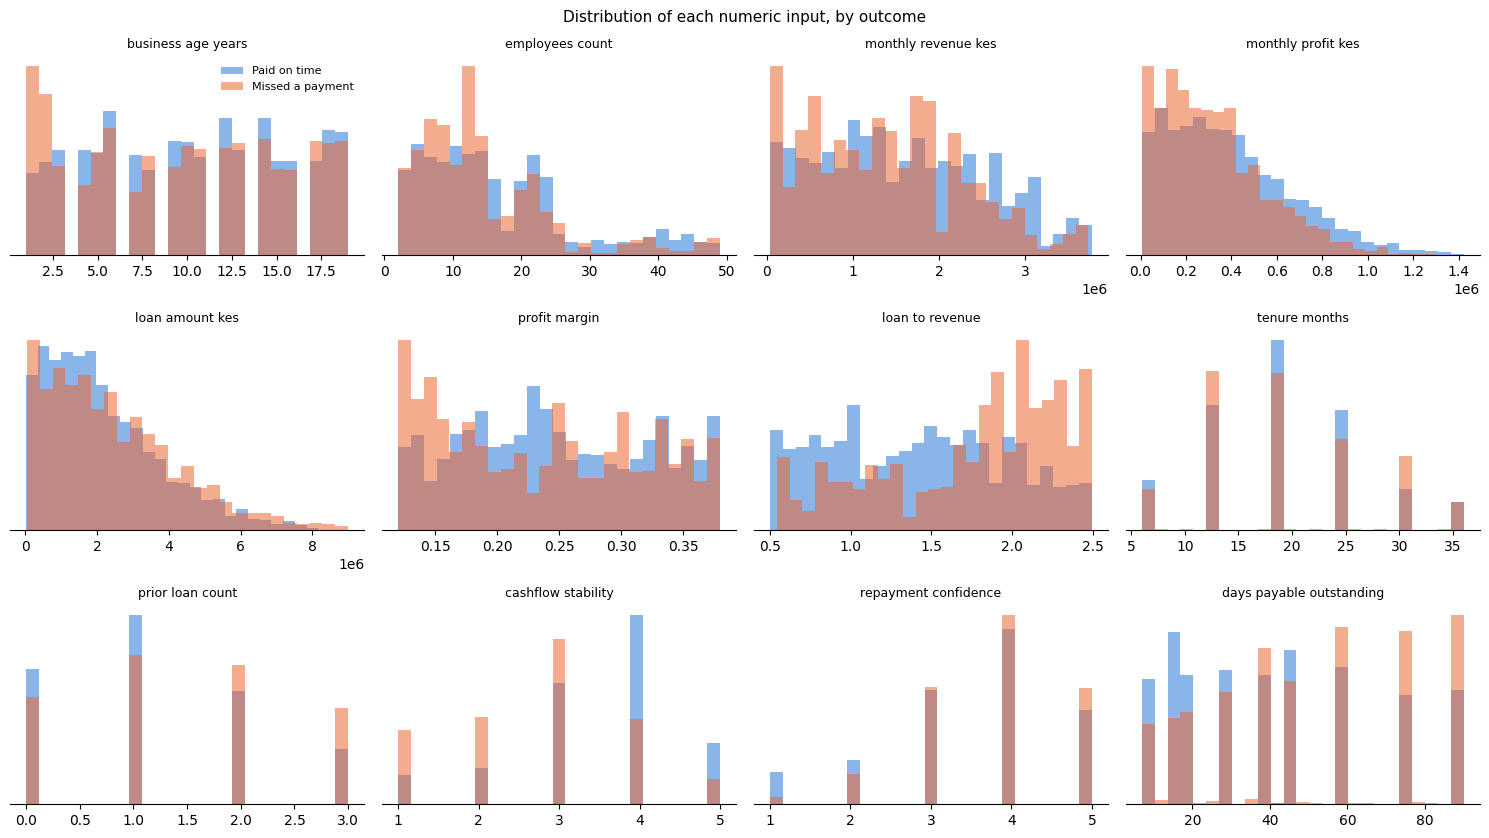

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, c in zip(axes.ravel(), NUM):
    for val, col, lab in [(0, "#2a78d6", "Paid on time"), (1, "#eb6834", "Missed a payment")]:
        ax.hist(eda.loc[eda[TARGET] == val, c], bins=25, alpha=0.55, color=col, density=True, label=lab)
    ax.set_title(c.replace("_", " "), fontsize=9); ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Distribution of each numeric input, by outcome", fontsize=11); plt.tight_layout(); plt.show()

Where the two shapes differ (for example cash-flow stability, loan size relative to revenue), the input helps separate the outcomes.

### Point-biserial correlation with the outcome

In [20]:
from scipy.stats import pointbiserialr, spearmanr, chi2_contingency
pb = pd.DataFrame({
    "synthetic_r": [pointbiserialr(eda[TARGET], eda[c])[0] for c in NUM],
    "synthetic_p": [pointbiserialr(eda[TARGET], eda[c])[1] for c in NUM],
    "real_r": [pointbiserialr(real_eda[TARGET], real_eda[c])[0] for c in NUM],
}, index=NUM).sort_values("synthetic_r", key=abs, ascending=False)
pb.round(4)

,synthetic_r,synthetic_p,real_r
cashflow_stability,-0.2851,0.0000,-0.2739
loan_to_revenue,0.2689,0.0000,0.2524
days_payable_outstanding,0.1533,0.0000,0.1300
monthly_profit_kes,-0.1227,0.0000,-0.1401
prior_loan_count,0.1221,0.0000,0.1454
repayment_confidence,0.1039,0.0000,0.0681
monthly_revenue_kes,-0.0901,0.0000,-0.1023
employees_count,-0.0845,0.0000,-0.0622
profit_margin,-0.0744,0.0000,-0.0942
loan_amount_kes,0.0655,0.0000,0.0444


Point-biserial *r* is the correlation between a numeric input and a yes/no outcome. A positive value means higher values go with more missed payments. The synthetic and real columns agree in sign and roughly in size, so the generator kept these relationships.

**Result:** repayment confidence has a small *positive* correlation with missed payments. In other words, owners who rated their confidence higher missed payments slightly more often. The pattern is already in the real source data (r ≈ +0.07), so the generator did not create it. It is weak, and it is plausibly over-optimism in self-reported answers, which is a known weakness of self-assessment questions in credit applications.

### Spearman correlation between inputs

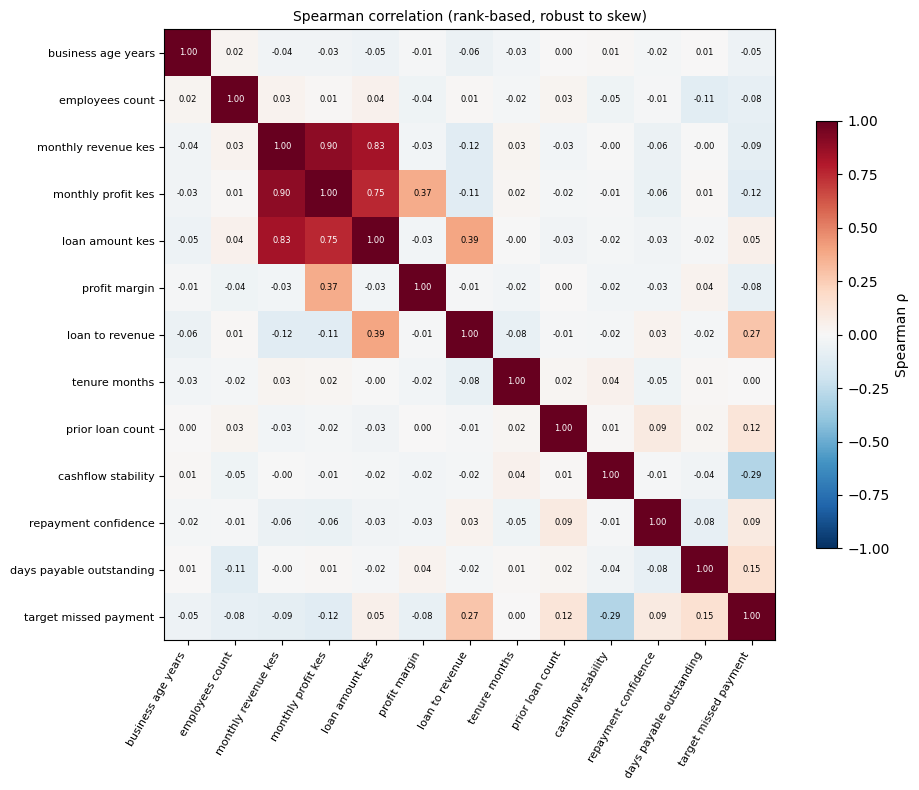

In [21]:
sp = eda[NUM + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sp.values, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [c.replace("_", " ") for c in sp.columns]
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(sp)):
    for j in range(len(sp)):
        ax.text(j, i, f"{sp.values[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(sp.values[i, j]) > 0.5 else "black")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ"); ax.set_title("Spearman correlation (rank-based, robust to skew)", fontsize=10)
plt.tight_layout(); plt.show()

Spearman correlation uses ranks, so the skewed money columns do not distort it. High correlations between inputs, such as revenue with profit or revenue with loan amount, are expected because they describe business size. Section A6.7 checks whether they cause a multicollinearity problem.

### Cramér's V for categorical inputs

In [22]:
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2, p = chi2_contingency(t, correction=False)[:2]
    return np.sqrt(chi2 / t.values.sum() / (min(t.shape) - 1)), p
cv_tab = pd.DataFrame([{"input": c, "synthetic_V": cramers_v(eda[c], eda[TARGET])[0],
                        "p_value": cramers_v(eda[c], eda[TARGET])[1],
                        "real_V": (cramers_v(real_eda[c], real_eda[TARGET])[0] if c != "county" else np.nan)}
                       for c in CAT]).set_index("input").sort_values("synthetic_V", ascending=False)
cv_tab.round(4)

,synthetic_V,p_value,real_V
input,,,
late_payment_history,0.3744,0.0000,0.4069
collateral_level,0.2306,0.0000,0.2139
location_type,0.1743,0.0000,0.1559
county,0.0998,0.3235,NaN
sector,0.0822,0.0000,0.0550
legal_status,0.0821,0.0000,0.0749
loan_purpose,0.0775,0.0000,0.0849
existing_loans,0.0640,0.0000,0.0715
owner_education,0.0432,0.0537,0.0352


Cramér's V measures association from 0 (none) to 1 (perfect). Late-payment history should lead. **County** is assigned at random within urban and rural areas, so any association it shows comes only through urban/rural location. That is why it is excluded from the model, and it has no "real" value.

### Weight of Evidence and Information Value



WoE and IV are the standard screening tools in credit scoring. For each group of an input, WoE = ln(share of good payers ÷ share of defaulters). IV sums the differences across groups into one number per input. Numeric inputs are split into five equal-sized bins.

| IV | Predictive strength |
|---|---|
| < 0.02 | not useful |
| 0.02–0.1 | weak |
| 0.1–0.3 | medium |
| 0.3–0.5 | strong |
| > 0.5 | very strong (check for leakage) |

In [23]:
def woe_iv(df, col, bins=5):
    s = pd.qcut(df[col], bins, duplicates="drop") if col in NUM and df[col].nunique() > bins else df[col]
    t = pd.crosstab(s, df[TARGET]).rename(columns={0: "good", 1: "bad"})
    g = (t.good + 0.5) / (t.good.sum() + 0.5); b = (t.bad + 0.5) / (t.bad.sum() + 0.5)   # 0.5 avoids log(0)
    t["WoE"] = np.log(g / b); t["IV_part"] = (g - b) * t.WoE
    return t, t.IV_part.sum()

def strength(v):
    return "not useful" if v < .02 else "weak" if v < .1 else "medium" if v < .3 else "strong" if v < .5 else "very strong"
iv = pd.DataFrame([{"input": c, "IV_synthetic": woe_iv(eda, c)[1],
                    "IV_real": (woe_iv(real_eda, c)[1] if c != "county" else np.nan)} for c in NUM + CAT]).set_index("input")
iv["strength"] = iv.IV_synthetic.apply(strength)
iv.sort_values("IV_synthetic", ascending=False).round(3)

,IV_synthetic,IV_real,strength
input,,,
late_payment_history,0.689,0.811,very strong
cashflow_stability,0.495,0.443,strong
loan_to_revenue,0.462,0.468,strong
collateral_level,0.272,0.231,medium
location_type,0.148,0.119,medium
days_payable_outstanding,0.134,0.096,medium
repayment_confidence,0.100,0.052,weak
profit_margin,0.097,0.109,weak
prior_loan_count,0.091,0.122,weak


In [24]:
woe_table, v = woe_iv(eda, "late_payment_history")
print(f"Late payment history: IV = {v:.3f}")
woe_table.round(3)

Late payment history: IV = 0.689


target_missed_payment,good,bad,WoE,IV_part
late_payment_history,,,,
Never,2771,471,0.684,0.251
Rarely,621,308,-0.387,0.030
Sometimes,348,481,-1.411,0.408


Negative WoE means more defaulters than average in that group, and positive WoE means fewer. For late-payment history, WoE falls steadily from "Never" to "Sometimes". This is the monotonic pattern a credit analyst expects, and it supports the ordinal encoding used in Part B.

### Mutual information

Measures how much knowing the value of a feature reduces uncertainty about the target variable

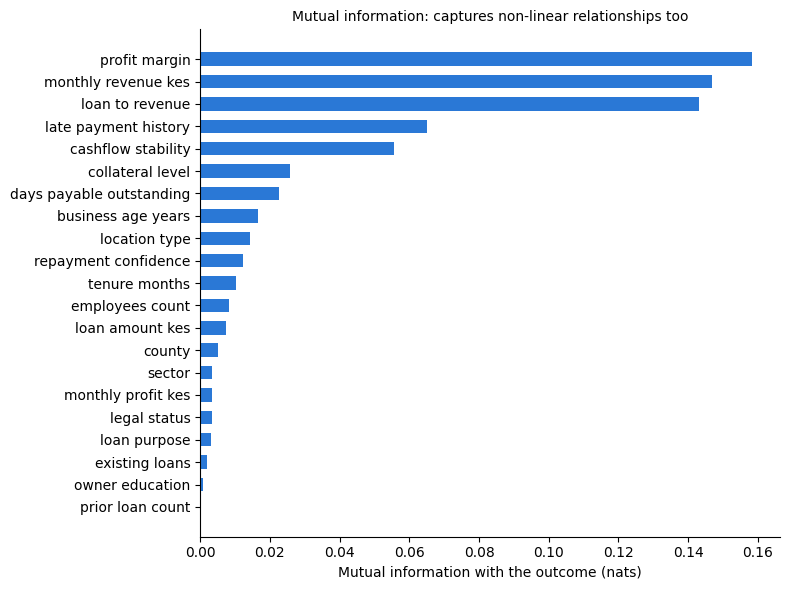

In [25]:
from sklearn.feature_selection import mutual_info_classif
mi_X = eda[NUM + CAT].copy()
for c in CAT: mi_X[c] = mi_X[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(mi_X, eda[TARGET], discrete_features=[c in CAT for c in mi_X.columns], random_state=SEED),
               index=mi_X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([c.replace("_", " ") for c in mi.index], mi.values, color="#2a78d6", height=0.6)
ax.set_xlabel("Mutual information with the outcome (nats)"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Mutual information: captures non-linear relationships too", fontsize=10); plt.tight_layout(); plt.show()

### Variance inflation factor (multicollinearity)

In [26]:
from sklearn.linear_model import LinearRegression
vif_cols = ["business_age_years", "employees_count", "monthly_revenue_kes", "profit_margin", "loan_amount_kes",
            "loan_to_revenue", "tenure_months", "prior_loan_count", "cashflow_stability",
            "repayment_confidence", "days_payable_outstanding"]
V = eda[vif_cols].astype(float)
vif = pd.Series({c: 1 / max(1e-9, 1 - LinearRegression().fit(V.drop(columns=c), V[c]).score(V.drop(columns=c), V[c]))
                 for c in vif_cols}, name="VIF").sort_values(ascending=False)
vif.round(2).to_frame()

,VIF
loan_amount_kes,9.57
monthly_revenue_kes,7.91
loan_to_revenue,3.73
repayment_confidence,1.03
days_payable_outstanding,1.02
employees_count,1.02
tenure_months,1.01
prior_loan_count,1.01
business_age_years,1.01
cashflow_stability,1.01


A VIF above 5 (strict) or 10 (lenient) means an input is largely predictable from the others. **Every input is below 5**, so multicollinearity is not a problem. The highest values belong to loan-to-revenue, loan amount and revenue, which are related by construction: loan-to-revenue = loan amount ÷ revenue. Monthly profit is left out of this check because the model uses profit margin instead.

### What the Exploratory Data analysis shows
- The data is complete, with no missing values and no duplicates. Employee count, profit and loan amount are right-skewed, and their outliers are plausible larger businesses, so they are kept.
- The strongest single signals are late-payment history, cash-flow stability, loan size relative to revenue and collateral. They lead on every measure: point-biserial, Cramér's V, IV and mutual information. Late-payment history scores IV ≈ 0.69 ("very strong"). This is not leakage: it describes payments before the loan being assessed, and the true leak, `missed_payment_last_12m`, was removed in section A1.1.
- Every measure gives similar values on synthetic and real rows, which confirms the generator kept the relationships.
- County shows some association with the outcome, but only because it was assigned according to urban or rural location, which does matter. It adds nothing of its own and is excluded from the model.
- All VIF values are below 5, so there is no multicollinearity problem.
- Repayment confidence correlates weakly with *more* missed payments. This is inherited from the source data and worth discussing as a limitation of self-reported inputs.

---
# Part B · Model training, evaluation and export


In [27]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb, shap
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, brier_score_loss)

SEED = 42
DATA_DIR = ""            # Colab: e.g. "/content/drive/MyDrive/Credit_Dataset/"
MODEL_VERSION = "xgb_msme_v2"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"

train_df = pd.read_csv(DATA_DIR + "kenya_msme_synthetic_v2.csv")
holdout_df = pd.read_csv(DATA_DIR + "real_holdout_240_kes.csv")
TARGET = "target_missed_payment"
print("Training:", train_df.shape, "default rate", round(train_df[TARGET].mean(), 3))
print("Holdout: ", holdout_df.shape, "default rate", round(holdout_df[TARGET].mean(), 3))

Training: (5000, 21) default rate 0.252
Holdout:  (240, 21) default rate 0.254


## Features
- **Excluded:** `business_id` (an identifier) and `county`. County was assigned at random within urban and rural areas in Part A, so it carries no real information. Using it would let the model fit noise and treat counties differently for no reason.
- **Derived:** `profit_margin` (profit ÷ revenue) and `loan_to_revenue` (loan amount ÷ monthly revenue). Ratios compare businesses of different sizes fairly.
- **Encoding:** ordered answers become ordered numbers, and yes/no becomes 0/1. Unordered categories (sector, legal status, location, loan purpose) become integer codes for the tree models. Trees split on them without assuming an order, and SHAP then gives one value per original question, which keeps explanations readable. Logistic regression gets one-hot columns instead.

In [28]:
ORDINAL_MAPS = {
    "late_payment_history": {"Never": 0, "Rarely": 1, "Sometimes": 2},
    "collateral_level": {"Low": 0, "Moderate": 1, "High": 2},
    "owner_education": {"Primary": 0, "Secondary": 1, "Higher Secondary": 2, "Bachelor's": 3, "Master's": 4},
    "existing_loans": {"No": 0, "Yes": 1},
}
NOMINAL_CATEGORIES = {c: sorted(train_df[c].unique().tolist())
                      for c in ["sector", "legal_status", "location_type", "loan_purpose"]}
FEATURES = [
    "sector", "legal_status", "location_type", "loan_purpose",
    "business_age_years", "employees_count", "monthly_revenue_kes", "profit_margin",
    "loan_amount_kes", "loan_to_revenue", "tenure_months",
    "existing_loans", "prior_loan_count", "late_payment_history", "collateral_level",
    "cashflow_stability", "repayment_confidence", "owner_education", "days_payable_outstanding",
]
FEATURE_LABELS = {
    "sector": "Sector", "legal_status": "Legal structure", "location_type": "Urban or rural",
    "loan_purpose": "Loan purpose", "business_age_years": "Business age", "employees_count": "Employees",
    "monthly_revenue_kes": "Monthly revenue", "profit_margin": "Profit margin",
    "loan_amount_kes": "Loan amount", "loan_to_revenue": "Loan size relative to revenue",
    "tenure_months": "Repayment period", "existing_loans": "Has existing loans",
    "prior_loan_count": "Number of previous loans", "late_payment_history": "Late payment history",
    "collateral_level": "Collateral", "cashflow_stability": "Cash-flow stability",
    "repayment_confidence": "Repayment confidence", "owner_education": "Owner education",
    "days_payable_outstanding": "Days taken to pay suppliers",
}

def prepare(df):
    """Turn raw rows into model features. The Django service must do exactly this."""
    X = pd.DataFrame(index=df.index)
    for c, cats in NOMINAL_CATEGORIES.items():
        unknown = set(df[c]) - set(cats)
        if unknown: raise ValueError(f"Unknown {c}: {unknown}")
        X[c] = df[c].map({k: i for i, k in enumerate(cats)})
    for c in ["business_age_years", "employees_count", "monthly_revenue_kes", "loan_amount_kes",
              "tenure_months", "prior_loan_count", "cashflow_stability", "repayment_confidence",
              "days_payable_outstanding"]:
        X[c] = df[c].astype(float)
    X["profit_margin"] = df["monthly_profit_kes"] / df["monthly_revenue_kes"]
    X["loan_to_revenue"] = df["loan_amount_kes"] / df["monthly_revenue_kes"]
    for c, m in ORDINAL_MAPS.items():
        X[c] = df[c].map(m)
        if X[c].isna().any(): raise ValueError(f"Unknown value in {c}")
    return X[FEATURES].astype(float)

X, y = prepare(train_df), train_df[TARGET].values
X_hold, y_hold = prepare(holdout_df), holdout_df[TARGET].values
X.describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
sector,1.62,0.00,3.00
legal_status,1.27,0.00,2.00
location_type,0.77,0.00,1.00
loan_purpose,1.92,0.00,4.00
business_age_years,10.10,1.00,19.00
employees_count,15.94,2.00,49.00
monthly_revenue_kes,1540533.14,38300.00,3772000.00
profit_margin,0.25,0.12,0.38
loan_amount_kes,2250724.80,25000.00,9000000.00
loan_to_revenue,1.50,0.50,2.49


## Comparing models with 5-fold cross-validation
All three are scored on the same five splits of the **training** data. Class weighting is not used yet. The model's probability is shown to applicants as a probability of default, so it should stay calibrated, and weighting would inflate it.

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nominal = list(NOMINAL_CATEGORIES)
numeric = [f for f in FEATURES if f not in nominal]
logreg = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), numeric),
                                              ("cat", OneHotEncoder(handle_unknown="ignore"), nominal)])),
                   ("clf", LogisticRegression(max_iter=3000))])
candidates = {
    "Logistic regression": logreg,
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "XGBoost (default settings)": xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                                    random_state=SEED, eval_metric="logloss"),
}
scoring = {"AUC": "roc_auc", "PR-AUC": "average_precision", "F1": "f1", "Precision": "precision", "Recall": "recall"}
rows = []
for name, m in candidates.items():
    r = cross_validate(m, X, y, cv=cv, scoring=scoring)
    rows.append({"model": name, **{k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}})
comparison = pd.DataFrame(rows).set_index("model"); comparison

,AUC,PR-AUC,F1,Precision,Recall
model,,,,,
Logistic regression,0.889 ± 0.012,0.744 ± 0.028,0.649 ± 0.022,0.731 ± 0.027,0.584 ± 0.031
Random forest,0.905 ± 0.005,0.778 ± 0.016,0.637 ± 0.030,0.797 ± 0.040,0.531 ± 0.033
XGBoost (default settings),0.916 ± 0.006,0.800 ± 0.020,0.699 ± 0.024,0.768 ± 0.024,0.643 ± 0.034


F1, precision and recall here use the default 0.5 cut-off. The cut-offs actually used for risk bands are chosen in section B4.

## Tune XGBoost
XGBoost is the model named in the project proposal. It is tuned with a randomised search, again using cross-validation on training data only.

In [30]:
search = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=SEED, eval_metric="logloss"),
    param_distributions={
        "n_estimators": [150, 250, 400, 600], "max_depth": [2, 3, 4, 5],
        "learning_rate": [0.02, 0.03, 0.05, 0.08], "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5, 10],
        "reg_lambda": [0.5, 1, 2, 5], "gamma": [0, 0.1, 0.3],
    },
    n_iter=40, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1)
search.fit(X, y)
best_params = search.best_params_
print(f"Best cross-validated AUC: {search.best_score_:.3f}")
print("Best settings:", best_params)

Best cross-validated AUC: 0.925
Best settings: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.08, 'gamma': 0.3, 'colsample_bytree': 1.0}


### **Class Weighting**

Only about 25% of businesses missed a payment. A common fix for imbalance is to weight the minority class (`scale_pos_weight` = good ÷ bad ≈ 3). This compares the tuned model with and without weighting, using out-of-fold predictions on training data only.

In [31]:
spw = (y == 0).sum() / (y == 1).sum()
cmp_rows, oof_store = [], {}
for name, extra in [("Unweighted", {}), (f"Weighted (scale_pos_weight={spw:.2f})", {"scale_pos_weight": spw})]:
    m = xgb.XGBClassifier(**best_params, **extra, random_state=SEED, eval_metric="logloss")
    p = cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1]; oof_store[name] = p
    cmp_rows.append({"model": name, "AUC": roc_auc_score(y, p), "Brier score (lower is better)": brier_score_loss(y, p),
                     "mean predicted PD": p.mean(), "actual default rate": y.mean(),
                     "recall at PD>0.5": recall_score(y, p > 0.5), "precision at PD>0.5": precision_score(y, p > 0.5)})
pd.DataFrame(cmp_rows).set_index("model").round(3)

,AUC,Brier score (lower is better),mean predicted PD,actual default rate,recall at PD>0.5,precision at PD>0.5
model,,,,,,
Unweighted,0.925,0.092,0.250,0.252,0.674,0.784
Weighted (scale_pos_weight=2.97),0.925,0.104,0.338,0.252,0.835,0.669


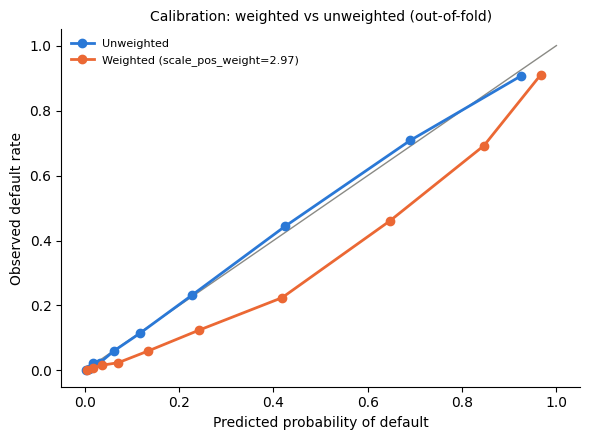

In [32]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 1], [0, 1], color=GREY, lw=1)
for (name, p), col in zip(oof_store.items(), [BLUE, ORANGE]):
    fr, mp = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", lw=2, color=col, label=name)
ax.set_xlabel("Predicted probability of default"); ax.set_ylabel("Observed default rate")
ax.set_title("Calibration: weighted vs unweighted (out-of-fold)", fontsize=10); ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

**Decision.** Weighting barely changes AUC, so ranking is unaffected. It does push predicted probabilities well above the true default rate: the weighted line sits under the diagonal, and its mean predicted PD exceeds the actual rate. It raises recall at a fixed 0.5 cut-off, but this system uses risk bands, not a fixed 0.5 cut-off, and shows the PD to users. The **unweighted** model is therefore kept. Imbalance is handled by setting the band cut-offs rather than by distorting the probabilities.

## Risk bands
The application turns probability of default (PD) into a score with `score = 850 − 550 × PD`, limited to 300–850. The score scale shown to users has three bands: **High risk 300–499, Moderate 500–699, Low risk 700–850**. These score boundaries convert directly into PD cut-offs:

- Low risk: score ≥ 700, so PD ≤ 0.2727
- High risk: score ≤ 499, so PD ≥ 0.6382

Here, the cut-offs are **checked** rather than tuned. The bands only make sense if the businesses placed in them really do default at clearly different rates. This is checked with *out-of-fold* predictions, where each training row is scored by a model that never saw it. The holdout is not used.

In [33]:
SCORE_MIN, SCORE_MAX, SCORE_SPAN = 300, 850, 550
LOW_MAX_PD = (SCORE_MAX - 700) / SCORE_SPAN        # 0.2727
HIGH_MIN_PD = (SCORE_MAX - 499) / SCORE_SPAN       # 0.6382

def to_score(pd_):  return np.clip(np.round(SCORE_MAX - pd_ * SCORE_SPAN), SCORE_MIN, SCORE_MAX).astype(int)
def to_band(pd_):   return np.where(pd_ <= LOW_MAX_PD, "Low Risk", np.where(pd_ >= HIGH_MIN_PD, "High Risk", "Moderate Risk"))

tuned = xgb.XGBClassifier(**best_params, random_state=SEED, eval_metric="logloss")
oof = cross_val_predict(tuned, X, y, cv=cv, method="predict_proba")[:, 1]
bands = pd.DataFrame({"band": to_band(oof), "default": y})
band_table = (bands.groupby("band")["default"].agg(applicants="size", default_rate="mean")
              .reindex(["Low Risk", "Moderate Risk", "High Risk"]))
band_table["share_of_applicants_%"] = (100 * band_table.applicants / len(bands)).round(1)
band_table["default_rate_%"] = (100 * band_table.default_rate).round(1)
print(f"Cut-offs: Low if PD <= {LOW_MAX_PD:.4f}, High if PD >= {HIGH_MIN_PD:.4f}")
print(f"Out-of-fold AUC: {roc_auc_score(y, oof):.3f}   Brier score: {brier_score_loss(y, oof):.3f}")
band_table[["applicants", "share_of_applicants_%", "default_rate_%"]]

Cut-offs: Low if PD <= 0.2727, High if PD >= 0.6382
Out-of-fold AUC: 0.925   Brier score: 0.092


,applicants,share_of_applicants_%,default_rate_%
band,,,
Low Risk,3391,67.8,6.0
Moderate Risk,770,15.4,45.2
High Risk,839,16.8,84.4


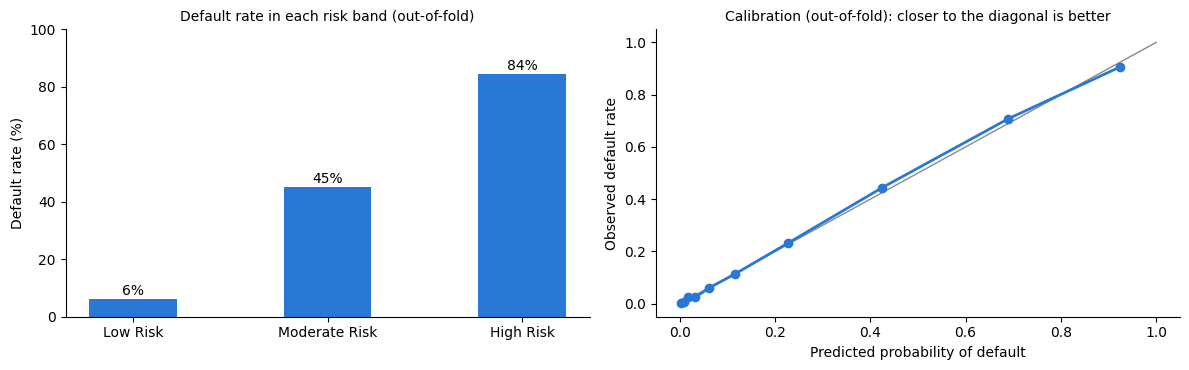

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bt = band_table["default_rate_%"]
axes[0].bar(bt.index, bt.values, width=0.45, color=BLUE)
for i, v in enumerate(bt.values): axes[0].text(i, v + 1.5, f"{v:.0f}%", ha="center")
axes[0].set_ylabel("Default rate (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title("Default rate in each risk band (out-of-fold)", fontsize=10)
frac, mean_pred = calibration_curve(y, oof, n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], color=GREY, lw=1)
axes[1].plot(mean_pred, frac, marker="o", color=BLUE, lw=2)
axes[1].set_xlabel("Predicted probability of default"); axes[1].set_ylabel("Observed default rate")
axes[1].set_title("Calibration (out-of-fold): closer to the diagonal is better", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

If the default rate rises clearly from Low to Moderate to High, the bands separate risk in a useful way. If the calibration line sits near the diagonal, a stated PD of 30% means about 30% of such businesses defaulted. The report should quote the band table above.

## Final model
The tuned settings are fitted on all 5,000 training rows. This exact fitted object is the one evaluated, explained and exported.

In [35]:
final_model = xgb.XGBClassifier(**best_params, random_state=SEED, eval_metric="logloss")
final_model.fit(X, y)
print("Trained on", X.shape[0], "rows and", X.shape[1], "features")

Trained on 5000 rows and 19 features


## Final test on the real holdout (run once)
The 240 real records were not used for any decision above. They are scored once here. Thresholded metrics use the boundary between **Low risk** and the other bands, which is where the system starts asking an analyst to look closely.

In [36]:
p_hold = final_model.predict_proba(X_hold)[:, 1]
flag = (p_hold > LOW_MAX_PD).astype(int)     # 1 = Moderate or High risk
cm = confusion_matrix(y_hold, flag)
test = {
    "roc_auc": roc_auc_score(y_hold, p_hold), "pr_auc": average_precision_score(y_hold, p_hold),
    "accuracy": accuracy_score(y_hold, flag), "brier": brier_score_loss(y_hold, p_hold),
}
per_class = [
    {"name": "On-time (0)", "precision": precision_score(y_hold, flag, pos_label=0),
     "recall": recall_score(y_hold, flag, pos_label=0), "f1": f1_score(y_hold, flag, pos_label=0)},
    {"name": "Missed payment (1)", "precision": precision_score(y_hold, flag),
     "recall": recall_score(y_hold, flag), "f1": f1_score(y_hold, flag)},
]
print({k: round(v, 3) for k, v in test.items()})
display(pd.DataFrame(per_class).set_index("name").round(3))
display(pd.DataFrame(cm, index=["Actual: on-time", "Actual: missed"],
                     columns=["Predicted: Low risk", "Predicted: Moderate/High"]))
hb = pd.DataFrame({"band": to_band(p_hold), "default": y_hold}).groupby("band")["default"] \
       .agg(applicants="size", default_rate="mean").reindex(["Low Risk", "Moderate Risk", "High Risk"])
hb["default_rate_%"] = (100 * hb.default_rate).round(1); hb[["applicants", "default_rate_%"]]

{'roc_auc': np.float64(0.862), 'pr_auc': np.float64(0.701), 'accuracy': 0.8, 'brier': np.float64(0.127)}


,precision,recall,f1
name,,,
On-time (0),0.892,0.832,0.861
Missed payment (1),0.589,0.705,0.642


,Predicted: Low risk,Predicted: Moderate/High
Actual: on-time,149,30
Actual: missed,18,43


,applicants,default_rate_%
band,,
Low Risk,167,10.8
Moderate Risk,46,50.0
High Risk,27,74.1


### ROC and precision-recall curves

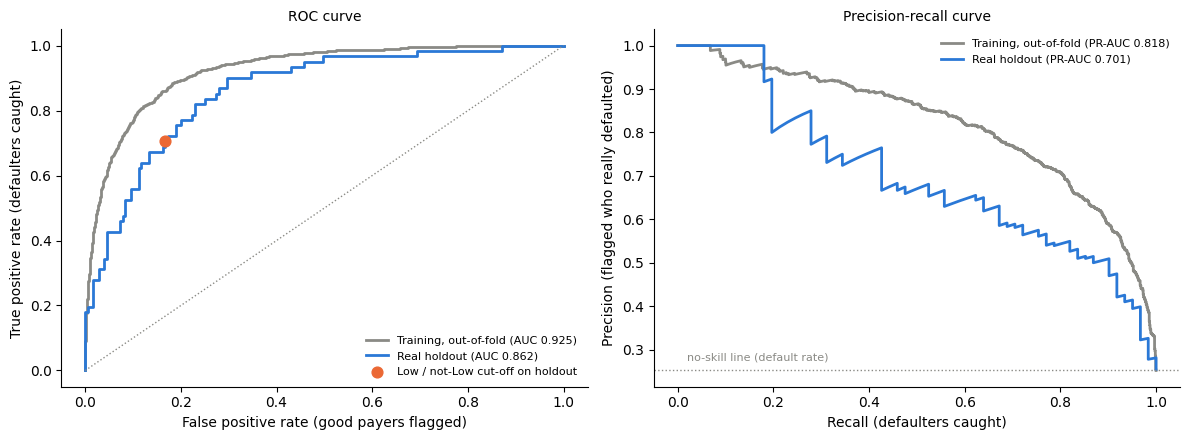

In [37]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for p, y_true, lab, col in [(oof, y, f"Training, out-of-fold (AUC {roc_auc_score(y, oof):.3f})", GREY),
                            (p_hold, y_hold, f"Real holdout (AUC {roc_auc_score(y_hold, p_hold):.3f})", BLUE)]:
    fpr, tpr, _ = roc_curve(y_true, p); axes[0].plot(fpr, tpr, lw=2, color=col, label=lab)
    pr, rc, _ = precision_recall_curve(y_true, p)
    axes[1].plot(rc, pr, lw=2, color=col, label=f"{lab.split(' (')[0]} (PR-AUC {average_precision_score(y_true, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, lw=1, ls=":")
axes[0].set_xlabel("False positive rate (good payers flagged)"); axes[0].set_ylabel("True positive rate (defaulters caught)")
axes[0].set_title("ROC curve", fontsize=10)
axes[1].axhline(y_hold.mean(), color=GREY, lw=1, ls=":")
axes[1].text(0.02, y_hold.mean() + 0.02, "no-skill line (default rate)", fontsize=8, color=GREY)
axes[1].set_xlabel("Recall (defaulters caught)"); axes[1].set_ylabel("Precision (flagged who really defaulted)")
axes[1].set_title("Precision-recall curve", fontsize=10)
lr_fpr = cm[0, 1] / cm[0].sum(); lr_tpr = cm[1, 1] / cm[1].sum()
axes[0].scatter([lr_fpr], [lr_tpr], s=60, color=ORANGE, zorder=3, label="Low / not-Low cut-off on holdout")
for a in axes: a.legend(frameon=False, fontsize=8, loc="lower right" if a is axes[0] else "upper right"); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

The grey curves come from synthetic training data (out-of-fold) and the blue curves from real held-out records. The gap between them is the optimism of validating on synthetic data. The orange point shows where the system actually operates: the share of defaulters caught against the share of good payers flagged at the Low-risk boundary.

## Explainability with SHAP
SHAP splits each prediction into a contribution per feature, measured in log-odds of default. A positive value raises the risk and a negative value lowers it. TreeExplainer computes these exactly for tree models.

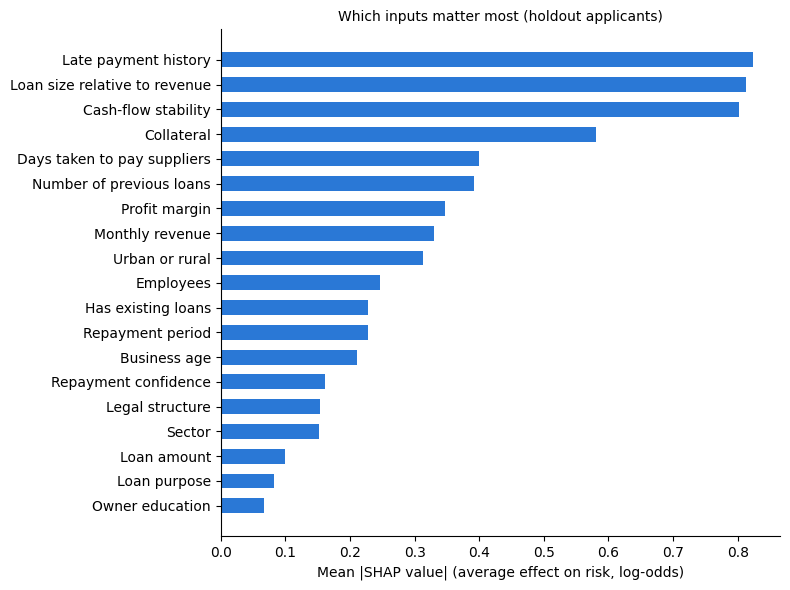

In [38]:
explainer = shap.TreeExplainer(final_model)
sv = explainer(X_hold)
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([FEATURE_LABELS[f] for f in mean_abs.index], mean_abs.values, color=BLUE, height=0.6)
ax.set_xlabel("Mean |SHAP value| (average effect on risk, log-odds)")
ax.set_title("Which inputs matter most (holdout applicants)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

/tmp/ipykernel_1844/2359758827.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv.values, X_hold, feature_names=[FEATURE_LABELS[f] for f in FEATURES], show=False)


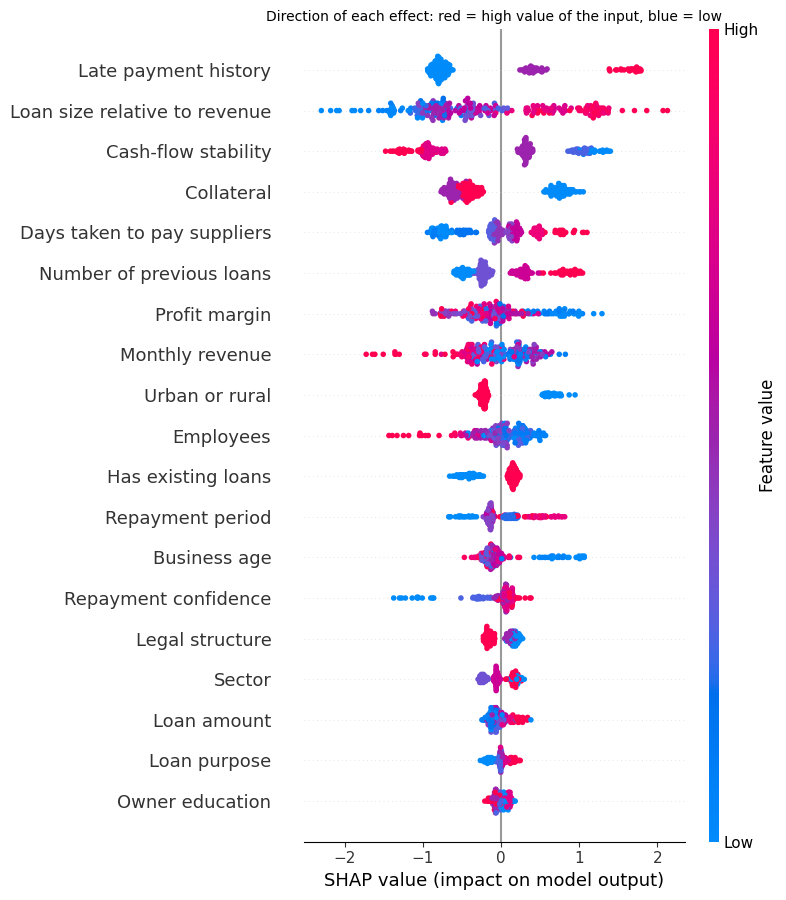

In [39]:
shap.summary_plot(sv.values, X_hold, feature_names=[FEATURE_LABELS[f] for f in FEATURES], show=False)
plt.title("Direction of each effect: red = high value of the input, blue = low", fontsize=10)
plt.tight_layout(); plt.show()

### Explanation for one applicant
The service stores one value per feature for every assessment. This function produces those values.

In [40]:
def explain(row_df, top=None):
    v = explainer(prepare(row_df)).values[0]
    out = [{"feature": f, "label": FEATURE_LABELS[f], "value": round(float(x), 4),
            "direction": "raises_risk" if x > 0 else "lowers_risk"} for f, x in zip(FEATURES, v)]
    out.sort(key=lambda d: abs(d["value"]), reverse=True)
    return out[:top] if top else out

example = holdout_df.iloc[[int(np.argmax(p_hold))]]
pd_ex = final_model.predict_proba(prepare(example))[:, 1][0]
print(f"Highest-risk holdout applicant: PD {pd_ex:.3f}, score {to_score(np.array([pd_ex]))[0]}, band {to_band(np.array([pd_ex]))[0]}")
pd.DataFrame(explain(example, top=6))

Highest-risk holdout applicant: PD 0.986, score 308, band High Risk


,feature,label,value,direction
0,loan_to_revenue,Loan size relative to revenue,2.0724,raises_risk
1,location_type,Urban or rural,0.9466,raises_risk
2,business_age_years,Business age,0.7998,raises_risk
3,collateral_level,Collateral,0.6884,raises_risk
4,repayment_confidence,Repayment confidence,-0.5132,lowers_risk
5,employees_count,Employees,0.3831,raises_risk


## Export for the Django service
Three files are written. A check then reloads them from disk and confirms they reproduce the in-notebook predictions exactly.

In [41]:
final_model.save_model("msme_xgboost_credit_model.json")

metadata = {
    "model_name": "XGBoost MSME credit scorer",
    "model_version": MODEL_VERSION,
    "target": TARGET,
    "features": FEATURES,
    "feature_labels": FEATURE_LABELS,
    "nominal_categories": NOMINAL_CATEGORIES,
    "nominal_encoding": "integer code = position in the category list",
    "ordinal_mappings": ORDINAL_MAPS,
    "derived_features": {
        "profit_margin": "monthly_profit_kes / monthly_revenue_kes",
        "loan_to_revenue": "loan_amount_kes / monthly_revenue_kes",
    },
    "excluded_columns": {"county": "randomly assigned in the synthetic data; carries no information",
                         "business_id": "identifier"},
    "score": {"formula": "clip(round(850 - 550 * pd), 300, 850)", "min": SCORE_MIN, "max": SCORE_MAX, "span": SCORE_SPAN},
    "risk_bands": [
        {"label": "Low Risk", "pd_max_inclusive": round(LOW_MAX_PD, 6), "score_range": "700-850"},
        {"label": "Moderate Risk", "pd_between": [round(LOW_MAX_PD, 6), round(HIGH_MIN_PD, 6)], "score_range": "500-699"},
        {"label": "High Risk", "pd_min_inclusive": round(HIGH_MIN_PD, 6), "score_range": "300-499"},
    ],
    "shap_units": "log-odds of default; positive raises risk",
    "training_rows": int(len(X)),
}
json.dump(metadata, open("model_metadata.json", "w"), indent=2)

report = {
    "source": "02_model_training.ipynb, tuned XGBoost, scored once on 240 held-out records",
    "data_note": "Trained on synthetic data generated from a Bangladeshi SME dataset (itself likely simulated) and "
                 "tested on its held-out records. These figures demonstrate the method; they do not predict "
                 "performance on real Kenyan MSME borrowers.",
    "test_rows": int(len(y_hold)),
    "classes": {"on_time": int((y_hold == 0).sum()), "default": int((y_hold == 1).sum())},
    "roc_auc": round(test["roc_auc"], 4), "pr_auc": round(test["pr_auc"], 4),
    "accuracy": round(test["accuracy"], 4), "brier": round(test["brier"], 4),
    "decision_point": f"Flagged = Moderate or High risk (PD > {LOW_MAX_PD:.4f})",
    "per_class": [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in pc.items()} for pc in per_class],
    "confusion_matrix": {"tn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "tp": int(cm[1, 1])},
    "cv_roc_auc": round(float(search.best_score_), 4),
    "oof_band_default_rates": {b: round(float(r), 4) for b, r in band_table["default_rate"].items()},
    "hyperparameters": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in best_params.items()},
    "model_version": MODEL_VERSION,
}
json.dump(report, open("model_report.json", "w"), indent=2)
print("Wrote msme_xgboost_credit_model.json, model_metadata.json, model_report.json")

Wrote msme_xgboost_credit_model.json, model_metadata.json, model_report.json


In [42]:
# Reload from disk and confirm identical predictions
reloaded = xgb.XGBClassifier(); reloaded.load_model("msme_xgboost_credit_model.json")
meta = json.load(open("model_metadata.json"))
assert meta["features"] == FEATURES
p_reload = reloaded.predict_proba(prepare(holdout_df)[meta["features"]])[:, 1]
assert np.allclose(p_reload, p_hold, atol=1e-6), "Exported model does not reproduce the notebook"
print("Export check passed:", len(p_reload), "holdout predictions match exactly.")

Export check passed: 240 holdout predictions match exactly.


## Summary of Part B
The numbers above are produced by this run. Quote them from the outputs, not from this text.

- **Comparison (section B2):** logistic regression, random forest and XGBoost were compared under 5-fold cross-validation on synthetic training data.
- **Tuning (section B3):** randomised search over XGBoost settings, scored by cross-validated AUC. Section B3.1 tests class weighting and shows the unweighted model gives better-calibrated probabilities with the same ranking ability.
- **Risk bands (section B4):** fixed by the score scale (300–499 / 500–699 / 700–850) and checked with out-of-fold predictions. Default rates rise from Low to High, and calibration is shown.
- **Final test (section B6):** one run on 240 real held-out records, which reports AUC, PR-AUC, the confusion matrix at the Low / not-Low boundary, default rates per band, and ROC and precision-recall curves (B6.1).
- **Explainability (section B7):** global importance, direction of effects, and per-applicant SHAP values in the format the system stores.

**Quote the holdout result, not the cross-validation result.** Cross-validation on synthetic data is optimistic, as the gap in section B6.1 shows. The 240 real records are the honest test.

**Limitations:**
1. The training data is synthetic, and its source appears simulated, so this is a demonstration of method.
2. The 240-record holdout is small, so its metrics carry wide uncertainty.
3. County is excluded because it carries no real information here. With real data, any location feature would need a fairness review.
4. The score formula is linear in PD. A lender would normally calibrate it to its own portfolio.

